# 🤖 Stacking Ensemble: XGBoost + Random Forest + TabNet

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Load and prepare dataset
df = pd.read_csv("/content/drive/MyDrive/UNSW-NB15-processed.csv")
df.drop(columns=['id', 'attack_cat', 'attack_ttp'], inplace=True)
df.drop_duplicates(inplace=True)

X = df.drop("label", axis=1)
y = LabelEncoder().fit_transform(df["label"])

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

## 🧠 Train Base Models: XGBoost, Random Forest, TabNet

In [5]:
import torch

In [8]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

# Train XGBoost
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Train TabNet
tabnet_model = TabNetClassifier()
tabnet_model.fit(
    X_train.values, y_train,
    eval_set=[(X_test.values, y_test)],
    eval_name=["val"],
    eval_metric=["accuracy"],
    max_epochs=10,
    patience=3,
    batch_size=1024, virtual_batch_size=128
)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:28:14] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.54563 | val_accuracy: 0.68261 |  0:00:03s
epoch 1  | loss: 0.36771 | val_accuracy: 0.83236 |  0:00:07s
epoch 2  | loss: 0.28838 | val_accuracy: 0.87017 |  0:00:10s
epoch 3  | loss: 0.22911 | val_accuracy: 0.91094 |  0:00:13s
epoch 4  | loss: 0.21249 | val_accuracy: 0.89677 |  0:00:16s
epoch 5  | loss: 0.19955 | val_accuracy: 0.91576 |  0:00:20s
epoch 6  | loss: 0.19474 | val_accuracy: 0.92253 |  0:00:23s
epoch 7  | loss: 0.19003 | val_accuracy: 0.92837 |  0:00:27s
epoch 8  | loss: 0.19134 | val_accuracy: 0.92818 |  0:00:30s
epoch 9  | loss: 0.18575 | val_accuracy: 0.93272 |  0:00:34s
Stop training because you reached max_epochs = 10 with best_epoch = 9 and best_val_accuracy = 0.93272


/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


## 🔄 Collect Predictions for Meta-Model

In [9]:
# Predict probabilities for stacking
xgb_preds = xgb_model.predict_proba(X_test)[:, 1]
rf_preds = rf_model.predict_proba(X_test)[:, 1]
tabnet_preds = tabnet_model.predict_proba(X_test.values)[:, 1]

# Combine into new feature set
stacked_X = np.vstack((xgb_preds, rf_preds, tabnet_preds)).T

## 🧠 Train Meta-Model (Logistic Regression)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

meta_model = LogisticRegression()
meta_model.fit(stacked_X, y_test)

final_preds = meta_model.predict(stacked_X)
print("Stacking Ensemble Accuracy:", accuracy_score(y_test, final_preds))

Stacking Ensemble Accuracy: 0.972384394402743


## 📊 Compare Base Models and Stacking Ensemble

               Model  Accuracy
0            XGBoost  0.973496
1      Random Forest  0.968122
2             TabNet  0.932722
3  Stacking Ensemble  0.972384


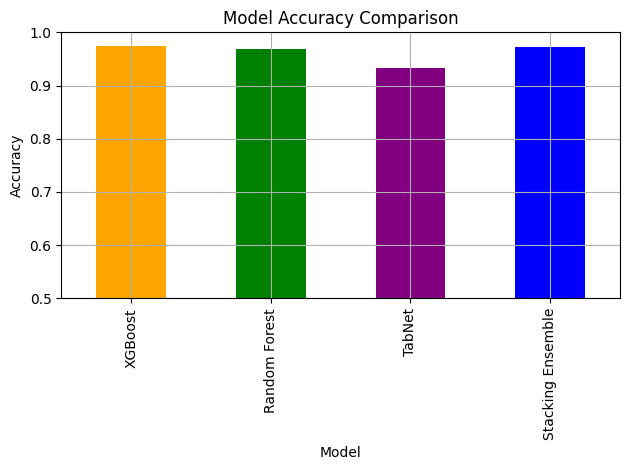

In [11]:
# Accuracy for all models
acc_xgb = accuracy_score(y_test, xgb_model.predict(X_test))
acc_rf = accuracy_score(y_test, rf_model.predict(X_test))
acc_tabnet = accuracy_score(y_test, tabnet_model.predict(X_test.values))
acc_stack = accuracy_score(y_test, final_preds)

# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Model': ['XGBoost', 'Random Forest', 'TabNet', 'Stacking Ensemble'],
    'Accuracy': [acc_xgb, acc_rf, acc_tabnet, acc_stack]
})

# Print and plot
print(comparison_df)

import matplotlib.pyplot as plt
comparison_df.plot(kind='bar', x='Model', y='Accuracy', legend=False, color=['orange', 'green', 'purple', 'blue'])
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0.5, 1.0)
plt.grid(True)
plt.tight_layout()
plt.show()

### 🧠 Interpretation
This bar chart shows the individual model performances and the combined stacking model.
The stacking ensemble often performs best because it learns from each model's strengths.

In [12]:
import time
import random
import pandas as pd
import numpy as np

# Sample live-like logs from X_test
print("🔍 Starting Live Threat Detection Simulation (Stacking Ensemble)...\n")
live_sample = X_test.sample(10, random_state=42)

for i, (_, row) in enumerate(live_sample.iterrows()):
    simulated_input = row.values.reshape(1, -1)

    # Get base model probabilities
    pred_xgb = xgb_model.predict_proba(simulated_input)[0, 1]
    pred_rf = rf_model.predict_proba(simulated_input)[0, 1]
    pred_tabnet = tabnet_model.predict_proba(simulated_input)[0, 1]

    # Stack for meta-model
    stacked_input = np.array([[pred_xgb, pred_rf, pred_tabnet]])

    # Final prediction from logistic regression meta-model
    final_prediction = meta_model.predict(stacked_input)[0]

    # Display prediction
    label = "🚨 Threat Detected!" if final_prediction == 1 else "✅ Normal Traffic"
    print(f"Log #{i+1}: {label}")

    time.sleep(1)

print("\n✅ Simulation Complete.")


🔍 Starting Live Threat Detection Simulation (Stacking Ensemble)...

Log #1: ✅ Normal Traffic


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Log #2: ✅ Normal Traffic


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Log #3: 🚨 Threat Detected!


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


... (9 outputs left out)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Log #9: 🚨 Threat Detected!


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Log #10: 🚨 Threat Detected!

✅ Simulation Complete.


In [13]:
import time
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
from datetime import datetime

print("🔍 Live Threat Detection (Stacking Ensemble) with Notifications...\n")
live_sample = X_test.sample(10, random_state=42)

for i, (idx, row) in enumerate(live_sample.iterrows()):
    simulated_input = row.values.reshape(1, -1)

    # Base model predictions
    pred_xgb = xgb_model.predict_proba(simulated_input)[0, 1]
    pred_rf = rf_model.predict_proba(simulated_input)[0, 1]
    pred_tabnet = tabnet_model.predict_proba(simulated_input)[0, 1]

    # Stack for meta model
    stacked_input = np.array([[pred_xgb, pred_rf, pred_tabnet]])
    final_pred = meta_model.predict(stacked_input)[0]

    # Current time
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    if final_pred == 1:
        # Display threat popup
        info = f"""
### 🚨 THREAT DETECTED!
- 🧾 Log #{i+1}
- ⏰ Time: {timestamp}
- 📌 Index: {idx}
- 🔎 Feature Sample: `{row.iloc[:5].to_dict()}`
        """
        display(Markdown(info))
    else:
        print(f"Log #{i+1} at {timestamp}: ✅ Normal Traffic")


🔍 Live Threat Detection (Stacking Ensemble) with Notifications...

Log #1 at 2025-06-26 11:49:49: ✅ Normal Traffic
Log #2 at 2025-06-26 11:49:49: ✅ Normal Traffic


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



### 🚨 THREAT DETECTED!
- 🧾 Log #3
- ⏰ Time: 2025-06-26 11:49:49
- 📌 Index: 8539
- 🔎 Feature Sample: `{'dur': -0.049374016, 'proto': 111.0, 'service': 5.0, 'state': 3.0, 'spkts': -0.019911597}`
        

Log #4 at 2025-06-26 11:49:49: ✅ Normal Traffic
Log #5 at 2025-06-26 11:49:49: ✅ Normal Traffic
Log #6 at 2025-06-26 11:49:49: ✅ Normal Traffic
Log #7 at 2025-06-26 11:49:49: ✅ Normal Traffic


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



### 🚨 THREAT DETECTED!
- 🧾 Log #8
- ⏰ Time: 2025-06-26 11:49:49
- 📌 Index: 9595
- 🔎 Feature Sample: `{'dur': -0.167470385, 'proto': 111.0, 'service': 5.0, 'state': 3.0, 'spkts': -0.064715957}`
        

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



### 🚨 THREAT DETECTED!
- 🧾 Log #9
- ⏰ Time: 2025-06-26 11:49:49
- 📌 Index: 47624
- 🔎 Feature Sample: `{'dur': -0.213728934, 'proto': 117.0, 'service': 0.0, 'state': 4.0, 'spkts': -0.124455103}`
        

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



### 🚨 THREAT DETECTED!
- 🧾 Log #10
- ⏰ Time: 2025-06-26 11:49:49
- 📌 Index: 44002
- 🔎 Feature Sample: `{'dur': -0.213728297, 'proto': 117.0, 'service': 0.0, 'state': 4.0, 'spkts': -0.124455103}`
        

The error `ModuleNotFoundError: No module named 'pytorch_tabnet'` indicates that the required Python library `pytorch_tabnet` is not installed. The following cell will install the library.

In [7]:
!pip install pytorch_tabnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 794.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 63.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstallin

After the installation is complete, please run the cell again to train the models.